## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [15]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Kevin Teng

**Date:** 10/17/2026

In [16]:
# Your Phase 1 solution to the problem goes here.

#Q1
token_freq[:5]

[('new', 1365),
 ('date', 1202),
 ('get', 1052),
 ('please', 1022),
 ('enron', 927)]

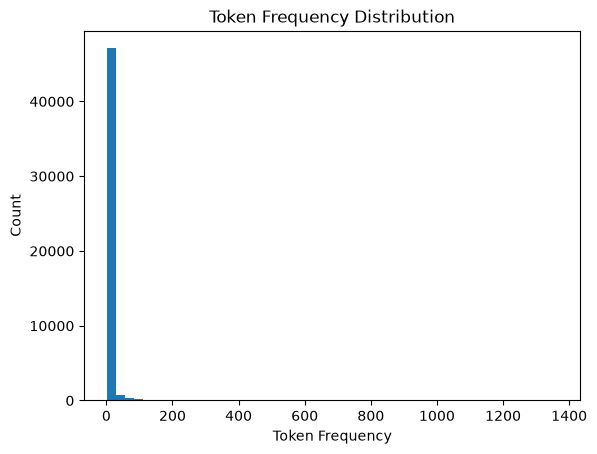

In [17]:
import matplotlib.pyplot as plt
plt.hist([count for _, count in token_freq], bins=50)
plt.xlabel('Token Frequency')
plt.ylabel('Count')
plt.title('Token Frequency Distribution')
plt.show()

Q1) The token frequency distribution heavily skews to the right, with ~47,000 tokens having a frequency of just 1 as indicated by the first bar. The distribution drops steeply with very little tokens appearing hundreds or thousands of times. The most frequent word, "new", has a frequency of 1365 which causes the histogram to extend further to the right.

In [18]:
#Q2 

import pandas as pd
df = pd.read_parquet("data/Phishing_clean.parquet")
df.head()

,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

x = df.drop(columns=['Email Type'])
y = df['Email Type']

#2.1 80/20 Test
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

model = LinearRegression()
model.fit(x_train, y_train)

#2.2 R^2 Score
training_set_r2 = model.score(x_train, y_train)
testing_set_r2 = model.score(x_test, y_test)
print("Training set R^2:", training_set_r2)
print("Testing set R^2:", testing_set_r2)




Training set R^2: 0.768699350041784
Testing set R^2: 0.6516549296925568


2.2) The R^2 on the training set is 0.768699350041784 and the R^2 on the test set is 0.6516549296925568

In [20]:
#2.3
coef = pd.Series(model.coef_, index=x.columns)
abs_coef = coef.abs()
print(abs_coef.nlargest(5))


background-image:    1.137598
aging                1.043082
localized            0.777854
helvetica,           0.660271
reversing            0.580435
dtype: float64


2.3) The words with the strongest influence are "background-image", "aging", "localized", "helvetica", and "reversing"

In [21]:
#Q3
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
x_pca = pca.fit_transform(x)

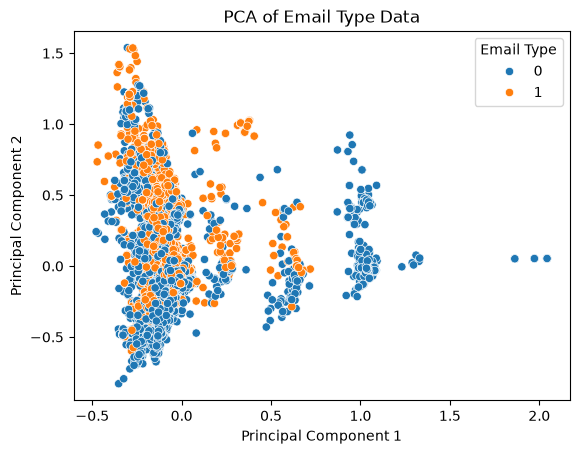

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x=x_pca[:, 0], y=x_pca[:, 1], hue=y)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Email Type Data')
plt.show()

3) The scatterplot shows overlap between email type 0 (non-phishing) and type 1 (phishing) emails, most prevalent when principal component 1 is lower (between -0.5 and 0). Real emails also form clusters on the far right side of the scatterplot and stand alone when principal component 1 is greater than or equal to 1. In contrast, phising emails do not have their own clusters, mixing with real emails and are concentrated on the left side of the plot, usually <= 0.5. 

In [23]:
#Q4
pca = PCA(n_components=2610)
x_train_pca = pca.fit_transform(x_train)
x_test_pca = pca.transform(x_test)
model_pca = LinearRegression()
model_pca.fit(x_train_pca, y_train)
testing_pca_r2 = model_pca.score(x_test_pca, y_test)
print("Testing set R^2 after PCA:", testing_pca_r2)
training_pca_r2 = model_pca.score(x_train_pca, y_train)
print("Training set R^2 after PCA:", training_pca_r2)


Testing set R^2 after PCA: 0.6529441933068718
Training set R^2 after PCA: 0.7679413296276345


4) the pca linear regression has a testing set R^2 of 0.6529441933068718 and a trainign set R^2 of 0.7679413296276345. These values are very close to the original linear regression with the pca training R^2 being slightly lower and the pca testing R^2 being slightly higher

5) Principal components reduce the number of features but keep the important features. This simplifies the overall regression by removing extraneous/overlapping information but still gives comparable results. In question 4, for example, the PCA regression had almost identical R^2 scores when compared to the original regression.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [24]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]